# Oral Disease Multi-Label Classification

## Setup & Imports

In [1]:
!pip install iterative-stratification

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random
import hashlib

import tensorflow as tf
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from tensorflow import keras
from tensorflow.keras import layers, callbacks, optimizers, losses
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dropout, BatchNormalization, Input, Dense, Rescaling
from sklearn.metrics import classification_report, precision_recall_curve, precision_score, recall_score, f1_score, average_precision_score
from tensorflow.keras.applications import EfficientNetB2, ResNet50, DenseNet121

## Data Exploration

In [3]:
base_dir = "/kaggle/input/datasets/salmansajid05/oral-diseases"

class_paths = {
    "Caries": os.path.join(
        base_dir, "Data caries", "Data caries",
        "caries orignal data set", "done"
    ),
    "Mouth Ulcer": os.path.join(
        base_dir, "Mouth Ulcer", "Mouth Ulcer",
        "ulcer original dataset", "ulcer original dataset"
    ),
    "Tooth Discoloration": os.path.join(
        base_dir, "Tooth Discoloration", "Tooth Discoloration ",
        "tooth discoloration original dataset",
        "tooth discoloration original dataset"
    ),
    "Gingivitis": os.path.join(
        base_dir, "Gingivitis", "Gingivitis"
    ),
    "Calculus": os.path.join(
        base_dir, "Calculus", "Calculus"
    ),
    "Hypodontia": os.path.join(
        base_dir, "hypodontia", "hypodontia"
    )
}

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

class_counts = {}

for class_name, folder_path in class_paths.items():
    files = os.listdir(folder_path)

    images = [
        file for file in files
        if file.lower().endswith(image_extensions)
    ]

    class_counts[class_name] = len(images)

counts_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["class", "no. of imgs"]
)

print(counts_df)

                 class  no. of imgs
0               Caries          219
1          Mouth Ulcer          265
2  Tooth Discoloration          183
3           Gingivitis         2349
4             Calculus         1296
5           Hypodontia         1251


### Images per Class

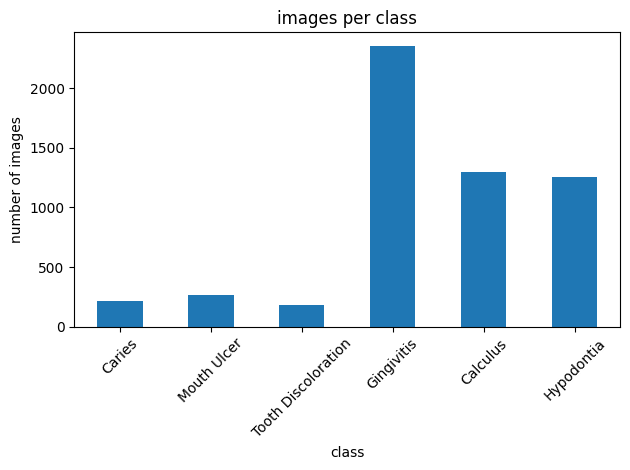

In [4]:
counts_df.plot(
    x="class",
    y="no. of imgs",
    kind="bar",
    legend=False
)

plt.xticks(rotation=45)
plt.ylabel("number of images")
plt.title("images per class")
plt.tight_layout()
plt.show()

### Sample Images

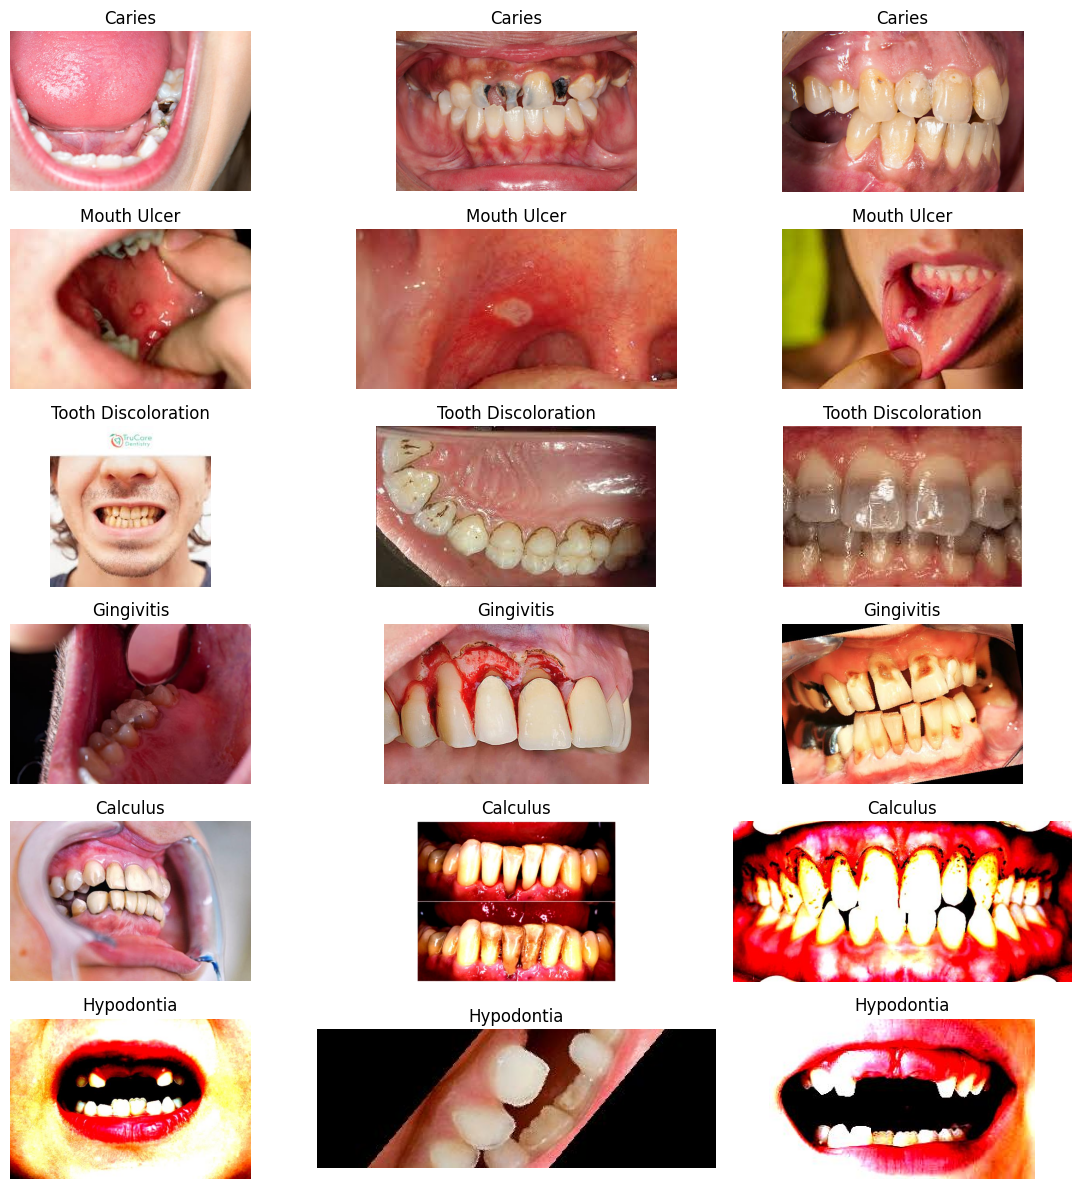

In [5]:
plt.figure(figsize=(12, 12))

for i, (class_name, folder_path) in enumerate(class_paths.items()):
    images = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith(image_extensions)
    ]

    samples = random.sample(images, min(3, len(images)))

    for j, image_name in enumerate(samples):
        image_path = os.path.join(folder_path, image_name)
        image = Image.open(image_path).convert("RGB")

        plt.subplot(6, 3, i * 3 + j + 1)
        plt.imshow(image)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

## Check Duplicates

In [6]:
image_hashes = {}

for class_name, folder_path in class_paths.items():
    for file_name in os.listdir(folder_path):
        if file_name.lower().endswith(image_extensions):
            image_path = os.path.join(folder_path, file_name)

            with open(image_path, "rb") as file:
                image_hash = hashlib.md5(file.read()).hexdigest()

            if image_hash not in image_hashes:
                image_hashes[image_hash] = []

            image_hashes[image_hash].append({
                "Class": class_name,
                "Path": image_path
            })

summary = []

for image_hash, images in image_hashes.items():
    classes = set(image["Class"] for image in images)

    if len(images) > 1:
        summary.append({
            "Hash": image_hash,
            "Copies": len(images),
            "Classes": ", ".join(sorted(classes)),
            "Different Classes": len(classes) > 1,
            "Paths": " | ".join(image["Path"] for image in images)
        })

summary_df = pd.DataFrame(summary)

print("Repeated image groups:", len(summary_df))
print("Groups in different classes:",
      summary_df["Different Classes"].sum())

display(summary_df[summary_df["Different Classes"] == True])


summary_df.to_csv("duplicates_summary.csv", index=False)

Repeated image groups: 775
Groups in different classes: 392


,Hash,Copies,Classes,Different Classes,Paths
4,a5771f1dd1dada718cec94c551182222,2,"Caries, Gingivitis",True,/kaggle/input/datasets/salmansajid05/oral-dise...
7,9692880dfa75bedd69e7e4ee74d7c221,4,"Calculus, Caries, Gingivitis",True,/kaggle/input/datasets/salmansajid05/oral-dise...
10,ef5b1147bab9d3a0ca858df7b24ca9ab,4,"Calculus, Caries, Gingivitis",True,/kaggle/input/datasets/salmansajid05/oral-dise...
11,527cdb3f6206a1641393145f4bbab1c9,7,"Calculus, Caries, Gingivitis",True,/kaggle/input/datasets/salmansajid05/oral-dise...
13,92eb03cddef3ced8d9ed2871e1ebd827,3,"Calculus, Caries",True,/kaggle/input/datasets/salmansajid05/oral-dise...
...,...,...,...,...,...
717,3ddc26717228923029c11a0668a68a5c,4,"Calculus, Hypodontia",True,/kaggle/input/datasets/salmansajid05/oral-dise...
729,1d35bac0fd894a5ef25de20847e2d74c,4,"Calculus, Hypodontia",True,/kaggle/input/datasets/salmansajid05/oral-dise...
740,ab15d1aec3f9b96323eb062ec92f8343,4,"Calculus, Hypodontia",True,/kaggle/input/datasets/salmansajid05/oral-dise...
752,144c9534262562efeea8848d3f7b0aed,4,"Calculus, Hypodontia",True,/kaggle/input/datasets/salmansajid05/oral-dise...


## Building Multi-Label Dataset

In [7]:
image_data = []

for image_hash, images in image_hashes.items():
    labels = set(image["Class"] for image in images)

    image_data.append({
        "Hash": image_hash,
        "Image_Path": images[0]["Path"],
        **{class_name: int(class_name in labels)
           for class_name in class_paths.keys()}
    })

labels_df = pd.DataFrame(image_data)

print("unique images:", len(labels_df))

print("\nimgs with each label:")
print(labels_df[list(class_paths.keys())].sum())

label_counts = labels_df[list(class_paths.keys())].sum(axis=1)

print("\nimgs with multiple labels:", (label_counts > 1).sum())
print("imgs with one label:", (label_counts == 1).sum())

display(labels_df[label_counts > 1].head(10))

unique images: 3899

imgs with each label:
Caries                  201
Mouth Ulcer             243
Tooth Discoloration     176
Gingivitis             1616
Calculus                829
Hypodontia             1242
dtype: int64

imgs with multiple labels: 392
imgs with one label: 3507


,Hash,Image_Path,Caries,Mouth Ulcer,Tooth Discoloration,Gingivitis,Calculus,Hypodontia
15,a5771f1dd1dada718cec94c551182222,/kaggle/input/datasets/salmansajid05/oral-dise...,1,0,0,1,0,0
20,9692880dfa75bedd69e7e4ee74d7c221,/kaggle/input/datasets/salmansajid05/oral-dise...,1,0,0,1,1,0
42,ef5b1147bab9d3a0ca858df7b24ca9ab,/kaggle/input/datasets/salmansajid05/oral-dise...,1,0,0,1,1,0
49,527cdb3f6206a1641393145f4bbab1c9,/kaggle/input/datasets/salmansajid05/oral-dise...,1,0,0,1,1,0
65,92eb03cddef3ced8d9ed2871e1ebd827,/kaggle/input/datasets/salmansajid05/oral-dise...,1,0,0,0,1,0
74,286dc34931535af42420c78172675cd5,/kaggle/input/datasets/salmansajid05/oral-dise...,1,0,0,1,0,0
76,472071cde4e53286060dba39a52cec61,/kaggle/input/datasets/salmansajid05/oral-dise...,1,0,0,1,1,0
78,3e525b08351d0d14a8fd5eb8ea17ca18,/kaggle/input/datasets/salmansajid05/oral-dise...,1,0,0,0,1,0
81,b062a50a19e26af1defb9ccd1a8f0f93,/kaggle/input/datasets/salmansajid05/oral-dise...,1,0,0,1,0,0
86,03a94b6cfd229bc7b6f91fc78bf9191c,/kaggle/input/datasets/salmansajid05/oral-dise...,1,0,0,0,1,0


### Label Distribution

In [8]:
label_columns = list(class_paths.keys())

label_counts = labels_df[label_columns].sum()

label_distribution = pd.DataFrame({
    "image count": label_counts,
    "percentage": (label_counts / len(labels_df) * 100).round(2)
})

display(label_distribution)

,image count,percentage
Caries,201,5.16
Mouth Ulcer,243,6.23
Tooth Discoloration,176,4.51
Gingivitis,1616,41.45
Calculus,829,21.26
Hypodontia,1242,31.85


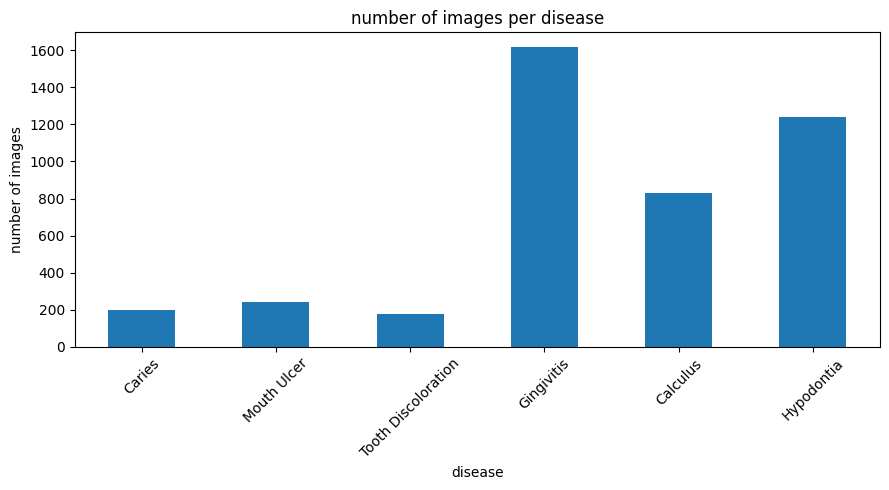

In [9]:
label_distribution["image count"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("number of images per disease")
plt.xlabel("disease")
plt.ylabel("number of images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Data Splitting

In [10]:
label_columns = list(class_paths.keys())

X = labels_df["Image_Path"]
y = labels_df[label_columns]

# Split 15% for testing
split1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_idx, test_idx = next(split1.split(X, y))

X_train_val = X.iloc[train_val_idx]
y_train_val = y.iloc[train_val_idx]

X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

# Split 15% of the full dataset for validation
split2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=42
)

train_idx, val_idx = next(split2.split(X_train_val, y_train_val))

X_train = X_train_val.iloc[train_idx]
y_train = y_train_val.iloc[train_idx]

X_val = X_train_val.iloc[val_idx]
y_val = y_train_val.iloc[val_idx]

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 2732
Validation images: 593
Testing images: 574


### Split Label Distribution

In [11]:
print("Train label distribution:")
print(y_train.sum())

print("\nValidation label distribution:")
print(y_val.sum())

print("\nTest label distribution:")
print(y_test.sum())

Train label distribution:
Caries                  141
Mouth Ulcer             170
Tooth Discoloration     124
Gingivitis             1131
Calculus                581
Hypodontia              870
dtype: int64

Validation label distribution:
Caries                  30
Mouth Ulcer             37
Tooth Discoloration     26
Gingivitis             243
Calculus               124
Hypodontia             186
dtype: int64

Test label distribution:
Caries                  30
Mouth Ulcer             36
Tooth Discoloration     26
Gingivitis             242
Calculus               124
Hypodontia             186
dtype: int64


## Handling Class Imbalance (Oversampling)

In [12]:
# Oversampling
n_before = len(X_train)

freq = y_train.mean()
class_weights = np.maximum(1, np.sqrt(0.25 / freq))
weights = (y_train * class_weights).max(axis=1)

rng = np.random.default_rng(42)
idx = []

for i in range(n_before):
    count = int(weights.iloc[i])

    if rng.random() < weights.iloc[i] - count:
        count += 1

    idx.extend([i] * count)

X_train = X_train.iloc[idx].reset_index(drop=True)
y_train = y_train.iloc[idx].reset_index(drop=True)

print(n_before, "->", len(X_train))
print(y_train.sum())

2732 -> 3266
Caries                  313
Mouth Ulcer             340
Tooth Discoloration     288
Gingivitis             1149
Calculus                617
Hypodontia              871
dtype: int64


## Dataset Preparation

In [13]:
IMG_SIZE = 224
BATCH_SIZE = 32

y_train_array = y_train.to_numpy(dtype="float32")
y_val_array = y_val.to_numpy(dtype="float32")
y_test_array = y_test.to_numpy(dtype="float32")


def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)

    return image, label


def create_dataset(image_paths, labels, cache_name, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths.astype(str).to_numpy(), labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.cache(
        f"/kaggle/working/{cache_name}"
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(image_paths),
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


train_dataset = create_dataset(
    X_train, y_train_array,
    cache_name="train_cache",
    training=True
)

val_dataset = create_dataset(
    X_val, y_val_array,
    cache_name="val_cache"
)

test_dataset = create_dataset(
    X_test, y_test_array,
    cache_name="test_cache"
)

I0000 00:00:1793169345.581841      96 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793169345.585537      96 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [14]:
for images, labels in train_dataset.take(1):
    print("images shape:", images.shape)
    print("labels shape:", labels.shape)

images shape: (32, 224, 224, 3)
labels shape: (32, 6)


### Data Augmentation

In [15]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomTranslation(height_factor = 0.1,width_factor = 0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255)),
    tf.keras.layers.RandomContrast(0.1),
    tf.keras.layers.GaussianNoise(stddev =0.09),
])

### Callbacks (Custom CNN)

In [16]:
lr_callback = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5
)

stop_callback = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

model_ckpt = callbacks.ModelCheckpoint(
    "cnn_model.keras",
    monitor="val_loss",
    save_best_only=True
)

## Custom CNN

In [17]:
def build_cnn(input_shape=(224, 224, 3), num_classes=6):

    model = Sequential([
        Input(shape=input_shape),

        augment,
        Rescaling(1./255),

        # Block 1
        Conv2D(32, (3, 3), activation="relu", padding="same"),
        Conv2D(32, (3, 3), activation="relu", padding="same"),
        MaxPooling2D((2, 2)),

        # Block 2
        Conv2D(64, (3, 3), activation="relu", padding="same"),
        Conv2D(64, (3, 3), activation="relu", padding="same"),
        MaxPooling2D((2, 2)),

        # Block 3
        Conv2D(128, (3, 3), activation="relu", padding="same"),
        Conv2D(128, (3, 3), activation="relu", padding="same"),
        MaxPooling2D((2, 2)),

        # Block 4
        Conv2D(256, (3, 3), activation="relu", padding="same"),
        Conv2D(256, (3, 3), activation="relu", padding="same"),
        MaxPooling2D((2, 2)),

        # Block 5
        Conv2D(256, (3, 3), activation="relu", padding="same"),

        GlobalAveragePooling2D(),

        Dropout(0.4),
        Dense(128, activation="relu"),
        Dropout(0.3),

        Dense(num_classes, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=[
        "binary_accuracy",
        tf.keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
    )

    return model


cnn = build_cnn()
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,796,006 (6.85 MB)

 Trainable params: 1,796,006 (6.85 MB)

 Non-trainable params: 0 (0.00 B)

### Training

In [18]:
history = cnn.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=100,
    callbacks=[lr_callback, stop_callback, model_ckpt],
    verbose=1
)

Epoch 1/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 29s 155ms/step - binary_accuracy: 0.8067 - loss: 0.4708 - pr_auc: 0.2592 - val_binary_accuracy: 0.8184 - val_loss: 0.4138 - val_pr_auc: 0.3388 - learning_rate: 0.0010
Epoch 2/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 16s 136ms/step - binary_accuracy: 0.8164 - loss: 0.4522 - pr_auc: 0.2783 - val_binary_accuracy: 0.8184 - val_loss: 0.4063 - val_pr_auc: 0.3354 - learning_rate: 0.0010
Epoch 3/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 16s 136ms/step - binary_accuracy: 0.8167 - loss: 0.4488 - pr_auc: 0.2847 - val_binary_accuracy: 0.8184 - val_loss: 0.4077 - val_pr_auc: 0.3533 - learning_rate: 0.0010
Epoch 4/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 15s 138ms/step - binary_accuracy: 0.8159 - loss: 0.4421 - pr_auc: 0.3047 - val_binary_accuracy: 0.8184 - val_loss: 0.3971 - val_pr_auc: 0.3828 - learning_rate: 0.0010
Epoch 5/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 17s 139ms/step - binary_accuracy: 0.8142 - loss: 0.4312 - pr_auc: 0.3161 - val_binary_accuracy: 0.8184 - val_loss: 0.3880 - val

### Training Curves

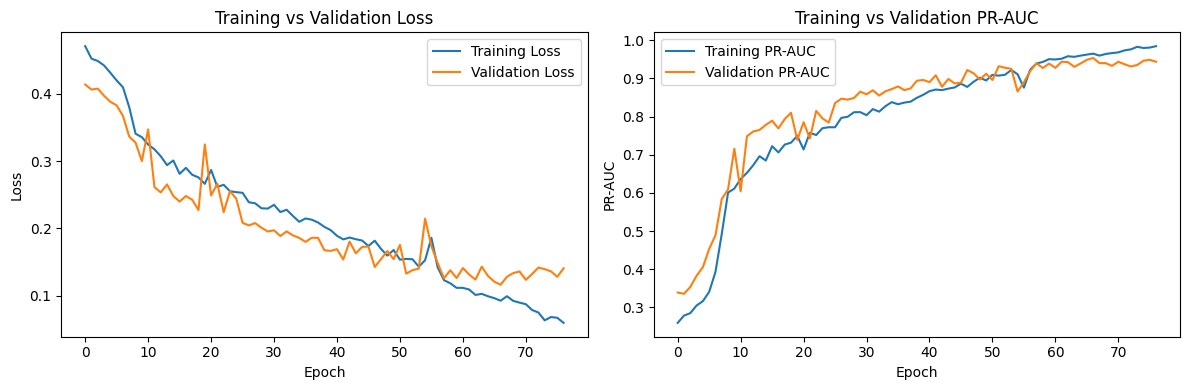

In [19]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training vs Validation Loss")

plt.subplot(1, 2, 2)
plt.plot(history.history["pr_auc"], label="Training PR-AUC")
plt.plot(history.history["val_pr_auc"], label="Validation PR-AUC")
plt.xlabel("Epoch")
plt.ylabel("PR-AUC")
plt.legend()
plt.title("Training vs Validation PR-AUC")

plt.tight_layout()
plt.show()

### Evaluation

In [20]:

probs = cnn.predict(val_dataset)
actual_labels = np.concatenate([y for x, y in val_dataset])

best_thresholds = []

for i in range(len(y_train.columns)):
    precision, recall, thresholds = precision_recall_curve(
        actual_labels[:, i],
        probs[:, i]
    )

    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    best_index = np.argmax(f1[:-1])
    best_thresholds.append(thresholds[best_index])

    print(
        y_train.columns[i],
        round(thresholds[best_index], 2),
        round(f1[best_index], 2)
    )

thr = np.array(best_thresholds)
print(classification_report(
    actual_labels, (probs >= thr).astype(int),
    target_names=y_train.columns, zero_division=0
))

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step
Caries 0.13 0.54
Mouth Ulcer 0.55 0.92
Tooth Discoloration 0.13 0.64
Gingivitis 0.51 0.94
Calculus 0.46 0.86
Hypodontia 0.27 0.95
                     precision    recall  f1-score   support

             Caries       0.45      0.67      0.54        30
        Mouth Ulcer       0.90      0.95      0.92        37
Tooth Discoloration       0.51      0.85      0.64        26
         Gingivitis       0.91      0.96      0.94       243
           Calculus       0.83      0.89      0.86       124
         Hypodontia       0.94      0.96      0.95       186

          micro avg       0.85      0.93      0.89       646
          macro avg       0.76      0.88      0.81       646
       weighted avg       0.87      0.93      0.89       646
        samples avg       0.89      0.94      0.90       646



## Transfer Learning

In [21]:
def make_callbacks(ckpt_path):
    return [
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5),
        callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        callbacks.ModelCheckpoint(ckpt_path, monitor="val_loss", save_best_only=True),
    ]

In [22]:
def unfreeze_top(base_model, n=30):
    base_model.trainable = True
    for layer in base_model.layers[:-n]:
        layer.trainable = False
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

### EfficientNetB2

In [23]:
num_classes = len(y_train.columns)

def build_effnet():

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    x = augment(inputs)

    base_model = EfficientNetB2(
        include_top=False,
        weights="imagenet",
        input_tensor=x
    )

    unfreeze_top(base_model)

    x = layers.GlobalAveragePooling2D(name="avg_pool")(base_model.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4, name="top_dropout")(x)

    outputs = layers.Dense(
        num_classes,
        activation="sigmoid",
        name="pred"
    )(x)

    model = tf.keras.Model(inputs, outputs, name="EfficientNetB2")

    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.0001),
        loss=losses.BinaryCrossentropy(),
        metrics=[
            "binary_accuracy",
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
    )

    return model


effnet = build_effnet()
effnet.summary()

31790344/31790344 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ sequential[1][0]  │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling_1[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_2[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati

 Total params: 7,782,655 (29.69 MB)

 Trainable params: 2,968,274 (11.32 MB)

 Non-trainable params: 4,814,381 (18.37 MB)

#### Training

In [24]:
history_effnet = effnet.fit(
    train_dataset, 
    validation_data=val_dataset, 
    epochs=100,
    callbacks=make_callbacks("best_effnet.keras"), 
    verbose=1
)

Epoch 1/100


E0000 00:00:1793170658.479482      96 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB2_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


103/103 ━━━━━━━━━━━━━━━━━━━━ 38s 196ms/step - binary_accuracy: 0.6193 - loss: 0.7578 - pr_auc: 0.4582 - val_binary_accuracy: 0.7465 - val_loss: 0.5463 - val_pr_auc: 0.7813 - learning_rate: 1.0000e-04
Epoch 2/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 18s 150ms/step - binary_accuracy: 0.7167 - loss: 0.5837 - pr_auc: 0.6744 - val_binary_accuracy: 0.8255 - val_loss: 0.4358 - val_pr_auc: 0.8508 - learning_rate: 1.0000e-04
Epoch 3/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 18s 150ms/step - binary_accuracy: 0.7600 - loss: 0.4987 - pr_auc: 0.7513 - val_binary_accuracy: 0.8690 - val_loss: 0.3633 - val_pr_auc: 0.8783 - learning_rate: 1.0000e-04
Epoch 4/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 17s 150ms/step - binary_accuracy: 0.8130 - loss: 0.4180 - pr_auc: 0.7992 - val_binary_accuracy: 0.8780 - val_loss: 0.3376 - val_pr_auc: 0.8787 - learning_rate: 1.0000e-04
Epoch 5/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 18s 150ms/step - binary_accuracy: 0.8449 - loss: 0.3645 - pr_auc: 0.8259 - val_binary_accuracy: 0.9126 - val_loss: 0.2726 -

#### Training Curves

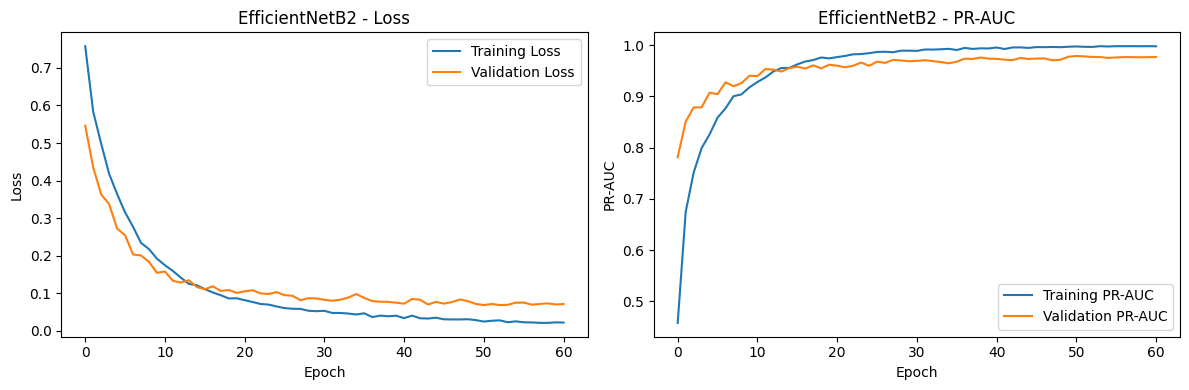

In [25]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_effnet.history["loss"], label="Training Loss")
plt.plot(history_effnet.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("EfficientNetB2 - Loss")

plt.subplot(1, 2, 2)
plt.plot(history_effnet.history["pr_auc"], label="Training PR-AUC")
plt.plot(history_effnet.history["val_pr_auc"], label="Validation PR-AUC")
plt.xlabel("Epoch")
plt.ylabel("PR-AUC")
plt.legend()
plt.title("EfficientNetB2 - PR-AUC")

plt.tight_layout()
plt.show()

#### Evaluation

In [26]:
probs_effnet = effnet.predict(val_dataset)

actual_labels = np.concatenate([
    labels.numpy() for images, labels in val_dataset
])

best_thresholds_effnet = []

for i in range(len(y_train.columns)):

    precision, recall, thresholds = precision_recall_curve(
        actual_labels[:, i],
        probs_effnet[:, i]
    )

    f1 = 2 * precision * recall / (precision + recall + 0.00000001)

    best_index = np.argmax(f1[:-1])
    best_thresholds_effnet.append(thresholds[best_index])

    print(
        y_train.columns[i],
        round(thresholds[best_index], 2),
        round(f1[best_index], 2)
    )

thr_effnet = np.array(best_thresholds_effnet)

pred_labels_effnet = (probs_effnet >= thr_effnet).astype(int)

print(classification_report(
    actual_labels,
    pred_labels_effnet,
    target_names=y_train.columns,
    zero_division=0
))

19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 268ms/step
Caries 0.02 0.63
Mouth Ulcer 0.08 0.96
Tooth Discoloration 0.08 0.83
Gingivitis 0.89 0.98
Calculus 0.62 0.95
Hypodontia 0.09 0.99
                     precision    recall  f1-score   support

             Caries       0.55      0.73      0.63        30
        Mouth Ulcer       0.93      1.00      0.96        37
Tooth Discoloration       0.81      0.85      0.83        26
         Gingivitis       0.98      0.98      0.98       243
           Calculus       0.94      0.96      0.95       124
         Hypodontia       0.98      0.99      0.99       186

          micro avg       0.94      0.97      0.95       646
          macro avg       0.86      0.92      0.89       646
       weighted avg       0.94      0.97      0.95       646
        samples avg       0.95      0.97      0.95       646



### ResNet50

In [27]:
num_classes = len(y_train.columns)

def build_resnet():

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    x = augment(inputs)

    base_model = ResNet50(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    unfreeze_top(base_model)

    x = layers.Lambda(tf.keras.applications.resnet50.preprocess_input, name="resnet_preprocess")(x)

    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D(name="avg_pool")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4, name="top_dropout")(x)

    outputs = layers.Dense(
        num_classes,
        activation="sigmoid",
        name="pred"
    )(x)

    model = tf.keras.Model(inputs, outputs, name="ResNet50")

    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.0001),
        loss=losses.BinaryCrossentropy(),
        metrics=[
            "binary_accuracy",
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
    )

    return model


resnet = build_resnet()
resnet.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocess (Lambda)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avg_pool                        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ top_dropout (Dropout)           │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pred (Dense)                    │ (None, 6)              │        12,294 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,608,198 (90.06 MB)

 Trainable params: 14,445,062 (55.10 MB)

 Non-trainable params: 9,163,136 (34.95 MB)

#### Training

In [28]:
history_resnet = resnet.fit(
    train_dataset, 
    validation_data=val_dataset, 
    epochs=100,
    callbacks=make_callbacks("best_resnet.keras"), 
    verbose=1
)

Epoch 1/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 36s 239ms/step - binary_accuracy: 0.6889 - loss: 0.6396 - pr_auc: 0.6458 - val_binary_accuracy: 0.8249 - val_loss: 0.4877 - val_pr_auc: 0.7753 - learning_rate: 1.0000e-04
Epoch 2/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 21s 192ms/step - binary_accuracy: 0.9585 - loss: 0.1339 - pr_auc: 0.9573 - val_binary_accuracy: 0.9609 - val_loss: 0.1419 - val_pr_auc: 0.9468 - learning_rate: 1.0000e-04
Epoch 8/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 22s 201ms/step - binary_accuracy: 0.9692 - loss: 0.1073 - pr_auc: 0.9699 - val_binary_accuracy: 0.9694 - val_loss: 0.1167 - val_pr_auc: 0.9584 - learning_rate: 1.0000e-04
Epoch 9/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 21s 192ms/step - binary_accuracy: 0.9722 - loss: 0.0953 - pr_auc: 0.9753 - val_binary_accuracy: 0.9674 - val_loss: 0.1382 - val_pr_auc: 0.9421 - learning_rate: 1.0000e-04
Epoch 10/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 21s 193ms/step - binary_accuracy: 0.9810 - loss: 0.0694 - pr_auc: 0.9832 - val_binary_accuracy: 0.9505 - val_l

#### Training Curves

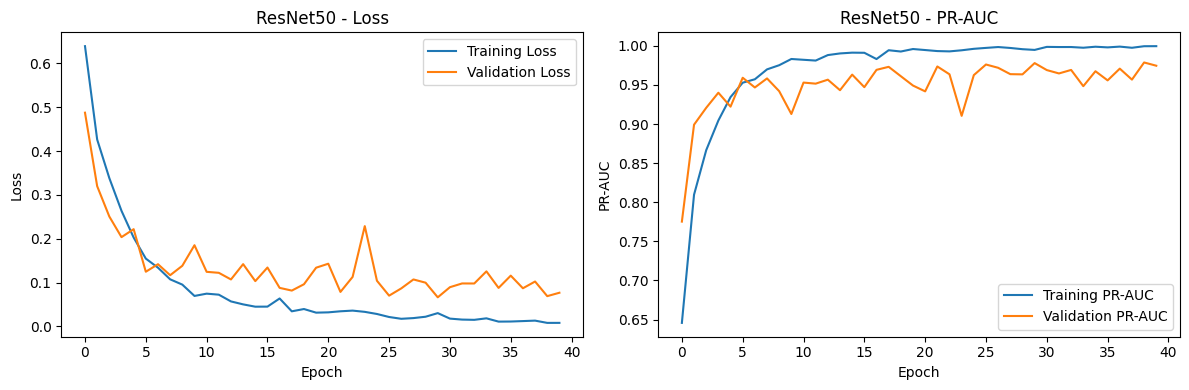

In [29]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_resnet.history["loss"], label="Training Loss")
plt.plot(history_resnet.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("ResNet50 - Loss")

plt.subplot(1, 2, 2)
plt.plot(history_resnet.history["pr_auc"], label="Training PR-AUC")
plt.plot(history_resnet.history["val_pr_auc"], label="Validation PR-AUC")
plt.xlabel("Epoch")
plt.ylabel("PR-AUC")
plt.legend()
plt.title("ResNet50 - PR-AUC")

plt.tight_layout()
plt.show()

#### Evaluation

In [30]:
probs_resnet = resnet.predict(val_dataset)

actual_labels = np.concatenate([
    labels.numpy() for images, labels in val_dataset
])

best_thresholds_resnet = []

for i in range(len(y_train.columns)):

    precision, recall, thresholds = precision_recall_curve(
        actual_labels[:, i],
        probs_resnet[:, i]
    )

    f1 = 2 * precision * recall / (precision + recall + 1e-8)

    best_index = np.argmax(f1[:-1])
    best_thresholds_resnet.append(thresholds[best_index])

    print(
        y_train.columns[i],
        round(thresholds[best_index], 2),
        round(f1[best_index], 2)
    )

thr_resnet = np.array(best_thresholds_resnet)

pred_labels_resnet = (probs_resnet >= thr_resnet).astype(int)

print(classification_report(
    actual_labels,
    pred_labels_resnet,
    target_names=y_train.columns,
    zero_division=0
))

19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 240ms/step
Caries 0.08 0.73
Mouth Ulcer 0.95 1.0
Tooth Discoloration 0.1 0.77
Gingivitis 0.12 0.98
Calculus 0.48 0.94
Hypodontia 0.43 0.99
                     precision    recall  f1-score   support

             Caries       0.80      0.67      0.73        30
        Mouth Ulcer       1.00      1.00      1.00        37
Tooth Discoloration       0.77      0.77      0.77        26
         Gingivitis       0.97      0.99      0.98       243
           Calculus       0.94      0.94      0.94       124
         Hypodontia       0.99      0.98      0.99       186

          micro avg       0.96      0.96      0.96       646
          macro avg       0.91      0.89      0.90       646
       weighted avg       0.95      0.96      0.95       646
        samples avg       0.95      0.96      0.95       646



### DenseNet121

In [31]:
num_classes = len(y_train.columns)

def build_densenet():

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    x = augment(inputs)

    x = layers.Lambda(tf.keras.applications.densenet.preprocess_input, name="densenet_preprocess")(x)

    base_model = DenseNet121(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    unfreeze_top(base_model)

    x = base_model(x, training=False)
    
    x = layers.GlobalAveragePooling2D(name="avg_pool")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4, name="top_dropout")(x)

    outputs = layers.Dense(
        num_classes,
        activation="sigmoid",
        name="pred"
    )(x)

    model = tf.keras.Model(inputs, outputs, name="DenseNet121")

    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.0001),
        loss=losses.BinaryCrossentropy(),
        metrics=[
            "binary_accuracy",
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
    )

    return model


densenet = build_densenet()
densenet.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DenseNet121"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet_preprocess (Lambda)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avg_pool                        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ top_dropout (Dropout)           │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pred (Dense)                    │ (None, 6)              │         6,150 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,047,750 (26.89 MB)

 Trainable params: 638,982 (2.44 MB)

 Non-trainable params: 6,408,768 (24.45 MB)

#### Training

In [32]:
history_dense = densenet.fit(
    train_dataset, 
    validation_data=val_dataset, 
    epochs=100,
    callbacks=make_callbacks("best_dense.keras"), 
    verbose=1
)

Epoch 1/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 41s 249ms/step - binary_accuracy: 0.5998 - loss: 0.7096 - pr_auc: 0.3763 - val_binary_accuracy: 0.7046 - val_loss: 0.5389 - val_pr_auc: 0.7234 - learning_rate: 1.0000e-04
Epoch 2/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 22s 190ms/step - binary_accuracy: 0.7061 - loss: 0.5669 - pr_auc: 0.6105 - val_binary_accuracy: 0.8221 - val_loss: 0.4057 - val_pr_auc: 0.7976 - learning_rate: 1.0000e-04
Epoch 3/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 22s 193ms/step - binary_accuracy: 0.7963 - loss: 0.4470 - pr_auc: 0.7225 - val_binary_accuracy: 0.8491 - val_loss: 0.3622 - val_pr_auc: 0.8390 - learning_rate: 1.0000e-04
Epoch 4/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 21s 186ms/step - binary_accuracy: 0.8527 - loss: 0.3574 - pr_auc: 0.7704 - val_binary_accuracy: 0.9129 - val_loss: 0.2714 - val_pr_auc: 0.8701 - learning_rate: 1.0000e-04
Epoch 5/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 21s 189ms/step - binary_accuracy: 0.8882 - loss: 0.2954 - pr_auc: 0.7995 - val_binary_accuracy: 0.9182 - val_lo

#### Training Curves

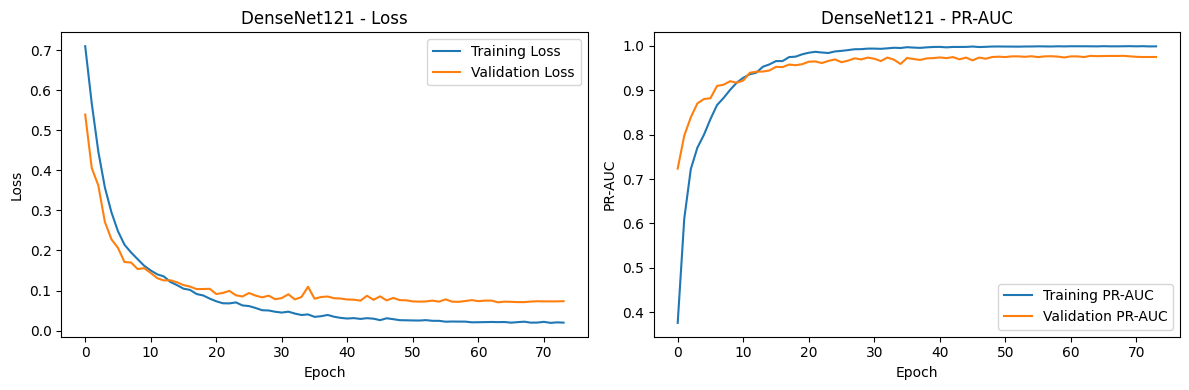

In [33]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_dense.history["loss"], label="Training Loss")
plt.plot(history_dense.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("DenseNet121 - Loss")

plt.subplot(1, 2, 2)
plt.plot(history_dense.history["pr_auc"], label="Training PR-AUC")
plt.plot(history_dense.history["val_pr_auc"], label="Validation PR-AUC")
plt.xlabel("Epoch")
plt.ylabel("PR-AUC")
plt.legend()
plt.title("DenseNet121 - PR-AUC")

plt.tight_layout()
plt.show()

#### Evaluation

In [34]:
probs_dense = densenet.predict(val_dataset)

actual_labels = np.concatenate([
    labels.numpy() for images, labels in val_dataset
])

best_thresholds_dense = []

for i in range(len(y_train.columns)):

    precision, recall, thresholds = precision_recall_curve(
        actual_labels[:, i],
        probs_dense[:, i]
    )

    f1 = 2 * precision * recall / (precision + recall + 1e-8)

    best_index = np.argmax(f1[:-1])
    best_thresholds_dense.append(thresholds[best_index])

    print(
        y_train.columns[i],
        round(thresholds[best_index], 2),
        round(f1[best_index], 2)
    )

thr_dense = np.array(best_thresholds_dense)

pred_labels_dense = (probs_dense >= thr_dense).astype(int)

print(classification_report(
    actual_labels,
    pred_labels_dense,
    target_names=y_train.columns,
    zero_division=0
))

19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 309ms/step
Caries 0.27 0.7
Mouth Ulcer 0.58 0.97
Tooth Discoloration 0.32 0.76
Gingivitis 0.47 0.98
Calculus 0.58 0.92
Hypodontia 0.33 0.98
                     precision    recall  f1-score   support

             Caries       0.79      0.63      0.70        30
        Mouth Ulcer       0.97      0.97      0.97        37
Tooth Discoloration       0.79      0.73      0.76        26
         Gingivitis       0.97      0.98      0.98       243
           Calculus       0.92      0.93      0.92       124
         Hypodontia       0.98      0.98      0.98       186

          micro avg       0.95      0.94      0.95       646
          macro avg       0.90      0.87      0.89       646
       weighted avg       0.95      0.94      0.95       646
        samples avg       0.94      0.95      0.94       646



## Model Comparison (Validation)

In [36]:
models = {
    "Custom CNN": (probs, thr),
    "EfficientNetB2": (probs_effnet, thr_effnet),
    "ResNet50": (probs_resnet, thr_resnet),
    "DenseNet121": (probs_dense, thr_dense),
}

rows = []
for name, (p, t) in models.items():
    pred = (p >= t).astype(int)
    rows.append({
        "model": name,
        "precision": precision_score(actual_labels, pred, average="macro", zero_division=0),
        "recall": recall_score(actual_labels, pred, average="macro", zero_division=0),
        "F1": f1_score(actual_labels, pred, average="macro"),
        "PR-AUC": average_precision_score(actual_labels, p, average="macro"),
    })

pd.DataFrame(rows).set_index("model").round(3)

,precision,recall,F1,PR-AUC
model,,,,
Custom CNN,0.759,0.878,0.808,0.848
EfficientNetB2,0.865,0.920,0.890,0.931
ResNet50,0.910,0.891,0.900,0.931
DenseNet121,0.905,0.871,0.886,0.915


## Hyperparameter Tuning (ResNet50)

In [38]:
num_classes = len(y_train.columns)

def build_resnet(n=30, lr=1e-4):

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    x = augment(inputs)

    base_model = ResNet50(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    unfreeze_top(base_model, n)

    x = layers.Lambda(tf.keras.applications.resnet50.preprocess_input, name="resnet_preprocess")(x)

    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D(name="avg_pool")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4, name="top_dropout")(x)

    outputs = layers.Dense(
        num_classes,
        activation="sigmoid",
        name="pred"
    )(x)

    model = tf.keras.Model(inputs, outputs, name="ResNet50")

    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss=losses.BinaryCrossentropy(),
        metrics=[
            "binary_accuracy",
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
    )

    return model

In [39]:
configs = [(30, 0.0001), (30, 0.00003), (30, 0.0003), (60, 0.0001), (100, 0.0001)]
results = []

for n_layers, lr in configs:
    model = build_resnet(n_layers, lr)

    model.fit(train_dataset, validation_data=val_dataset, epochs=100,
              callbacks=make_callbacks("tuning_resnet.keras"), verbose=0)

    val_probs = model.predict(val_dataset, verbose=0)
    score = average_precision_score(actual_labels, val_probs, average="macro")

    results.append((n_layers, lr, round(score, 3)))
    print(n_layers, lr, round(score, 3))

pd.DataFrame(results, columns=["layers", "lr", "PR-AUC"])

30 0.0001 0.936
30 3e-05 0.915
30 0.0003 0.93
60 0.0001 0.935
100 0.0001 0.931


,layers,lr,PR-AUC
0,30,0.00010,0.936
1,30,0.00003,0.915
2,30,0.00030,0.930
3,60,0.00010,0.935
4,100,0.00010,0.931


## Comparative Analysis

### Models compared

Four models were trained on the same data, with the same train/validation/test split, the same oversampling and augmentation and the same callbacks:

- **Custom CNN**: trained from scratch with a learning rate of 0.001
- **EfficientNetB2, ResNet50, DenseNet121**: pretrained on ImageNet, fine-tuned by unfreezing the top 30 layers (BatchNorm layers kept frozen) with a learning rate of 0.0001

The learning rate differs by model type because custom cnn and the pretrained ones need different step sizes

### Validation results 

#### macro average over the 6 diseases

| Model | Precision | Recall | F1 | PR-AUC |
|---|---|---|---|---|
| Custom CNN | 0.759 | 0.878 | 0.808 | 0.848 |
| EfficientNetB2 | 0.865 | 0.920 | 0.890 | 0.931 |
| ResNet50 | 0.910 | 0.891 | 0.900 | 0.931 |
| DenseNet121 | 0.905 | 0.871 | 0.886 | 0.915 |

#### F1 per disease

| Disease | Custom CNN | EfficientNetB2 | ResNet50 | DenseNet121 |
|---|---|---|---|---|
| Caries | 0.54 | 0.63 | 0.73 | 0.70 |
| Mouth Ulcer | 0.92 | 0.96 | 1.00 | 0.97 |
| Tooth Discoloration | 0.64 | 0.83 | 0.77 | 0.76 |
| Gingivitis | 0.94 | 0.98 | 0.98 | 0.98 |
| Calculus | 0.86 | 0.95 | 0.94 | 0.92 |
| Hypodontia | 0.95 | 0.99 | 0.99 | 0.98 |

### Discussion

- Pretrained models performed better than the custom CNN, with around 0.09 higher F1 and 0.08 higher PR-AUC

- ResNet50, EfficientNetB2, and DenseNet121 had similar results. ResNet50 achieved the best F1 and precision, while EfficientNetB2 had the highest recall

- Caries and Tooth Discoloration were the hardest classes due to having fewer validation images and Caries often appears together with Gingivitis or Calculus 
ResNet50 performed best on Caries

- Gingivitis, Hypodontia and Calculus (Large classes) had the best results across pretrained models.

- To handle class imbalance, i used moderate oversampling on the training set and tuned a separate threshold for each class using the validation set

- I selected ResNet50 for further tuning because it achieved the highest F1 and performed best on Caries


### Hyperparameter tuning (ResNet50)

| Unfrozen layers | Learning rate | PR-AUC |
|---|---|---|
| 30 | 1e-4 | 0.936 |
| 30 | 3e-5 | 0.915 |
| 30 | 3e-4 | 0.930 |
| 60 | 1e-4 | 0.935 |
| 100 | 1e-4 | 0.931 |

- I tested different learning rates and numbers of unfrozen layers using validation PR-AUC.

- A learning rate of 3e-5 gave the lowest score, while the other settings had very close results.

- I kept the original setting (30 layers, 0.0001) because it achieved the highest PR-AUC with the simplest configuration



### Limitations

- Caries and Tooth Discoloration have few validation images so their scores can change significantly with just one image

- Model selection and threshold tuning used the validation set so the test set is needed for a fair final evaluation

- Exact duplicate images were merged, but resized or augmented copies might still exist across splits

- Each configuration was trained only once so small differences may be due to training variation

### Final model

**ResNet50** -> 30 unfrozen layers, learning rate = 0.0001

## Final Evaluation on Test Set

In [40]:
test_labels = np.concatenate([y for _, y in test_dataset])

test_probs = resnet.predict(test_dataset)
test_pred = (test_probs >= thr_resnet).astype(int)

print(classification_report(
    test_labels, test_pred,
    target_names=y_train.columns, zero_division=0
))

print("PR-AUC:", round(average_precision_score(test_labels, test_probs, average="macro"), 3))

18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 169ms/step
                     precision    recall  f1-score   support

             Caries       0.66      0.70      0.68        30
        Mouth Ulcer       1.00      0.92      0.96        36
Tooth Discoloration       0.90      0.69      0.78        26
         Gingivitis       0.96      0.98      0.97       242
           Calculus       0.88      0.87      0.87       124
         Hypodontia       0.97      0.99      0.98       186

          micro avg       0.93      0.93      0.93       644
          macro avg       0.89      0.86      0.87       644
       weighted avg       0.93      0.93      0.93       644
        samples avg       0.94      0.94      0.93       644

PR-AUC: 0.929


### Final Test Results (ResNet50)

The test set was evaluated once (using the thresholds fixed on the validation set)

Precision 0.89            
Recall 0.86                 
F1 0.87                 
PR-AUC 0.929                      

**Validation vs test.** 

- Macro F1 dropped from 0.90 to 0.87 while PR-AUC stayed almost the same (0.931 vs 0.929)

- Mouth Ulcer and Calculus had the biggest F1 drops while Caries (0.68) and Tooth Discoloration (0.78) remained the hardest classes

- Tooth Discoloration had high precision (0.90) but lower recall (0.69) meaning some cases were missed

## Conclusion

Pretrained CNNs performed better than the custom CNN, with a validation macro F1 of 0.89–0.90 compared to 0.81.

ResNet50 achieved a test macro F1 of 0.87 and micro F1 of 0.93.

The model performed well on common classes, but Caries and Tooth Discoloration still need improvement.


## Save Model

In [41]:
resnet.save("resnet_final.keras")

thresholds = dict(zip(y_train.columns, np.array(thr_resnet).tolist()))

with open("thresholds.json", "w") as f:
    f.write(json.dumps(thresholds))

print(tf.__version__)

2.20.0
